# Global Crop Yield Shock Prediction
### An End-to-End Comparative Benchmark & Sparsity Analysis
**Author:** Samman Bhetwal  
**Domain:** Precision Agriculture / Food Security AI  
**Goal:** Predict localized crop yield shocks using FAO historical climate and production records across 101 countries and 10 major crops.

In [30]:
import ipykernel
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid")

## 1. Exploratory Data Analysis & Group-Relative Target Formulation

In [31]:
data_path = "data/df_yield_merged.csv"
df = pd.read_csv(data_path)

print("Dataset Shape", df.shape)

df.head()

Dataset Shape (25932, 7)


,area,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,item,value_hg_ha
0,Albania,1990,1485.0,121.0,16.37,Maize,36613
1,Albania,1990,1485.0,121.0,16.37,Potatoes,66667
2,Albania,1990,1485.0,121.0,16.37,"Rice, paddy",23333
3,Albania,1990,1485.0,121.0,16.37,Sorghum,12500
4,Albania,1990,1485.0,121.0,16.37,Soybeans,7000


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25932 entries, 0 to 25931
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   area                           25932 non-null  str    
 1   year                           25932 non-null  int64  
 2   average_rain_fall_mm_per_year  25932 non-null  float64
 3   pesticides_tonnes              25932 non-null  float64
 4   avg_temp                       25932 non-null  float64
 5   item                           25932 non-null  str    
 6   value_hg_ha                    25932 non-null  int64  
dtypes: float64(3), int64(2), str(2)
memory usage: 1.4 MB


In [33]:
df.nunique()

area                               101
year                                23
average_rain_fall_mm_per_year      100
pesticides_tonnes                 1673
avg_temp                          1831
item                                10
value_hg_ha                      11514
dtype: int64

In [34]:
df.describe()
df.describe(include='all')

,area,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,item,value_hg_ha
count,25932,25932.000000,25932.000000,25932.000000,25932.000000,25932,25932.000000
unique,101,NaN,NaN,NaN,NaN,10,NaN
top,India,NaN,NaN,NaN,NaN,Potatoes,NaN
freq,3384,NaN,NaN,NaN,NaN,3956,NaN
mean,NaN,2001.556455,1146.836688,34782.573241,20.422251,NaN,76978.132925
std,NaN,7.055924,717.391098,57228.568244,6.439402,NaN,84647.605552
min,NaN,1990.000000,51.000000,0.040000,1.300000,NaN,50.000000
25%,NaN,1995.000000,593.000000,1597.000000,16.580000,NaN,19996.000000
50%,NaN,2001.000000,1083.000000,15373.000000,21.420000,NaN,39530.000000
75%,NaN,2008.000000,1668.000000,45620.000000,26.060000,NaN,104168.000000


In [35]:
df.isnull().sum()

area                             0
year                             0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
item                             0
value_hg_ha                      0
dtype: int64

In [36]:
group_medians = df.groupby(['area', 'item'])['value_hg_ha'].transform('median')

df['yield_shock'] = (df['value_hg_ha'] < group_medians).astype(int)

print("Raw Counts:")
print(df['yield_shock'].value_counts())

print("Percentage Balance:")
print(df['yield_shock'].value_counts(normalize=True))

Raw Counts:
yield_shock
0    13624
1    12308
Name: count, dtype: int64
Percentage Balance:
yield_shock
0    0.525374
1    0.474626
Name: proportion, dtype: float64


/var/folders/r2/l9xjclp174zf83lxsxgmwyjr0000gn/T/ipykernel_75444/1536971298.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Normal harvest (0)', 'Yield Shock (1)'])


Text(0.5, 1.0, 'Target Distribution: Normal Harvest vs. Yield Shock')

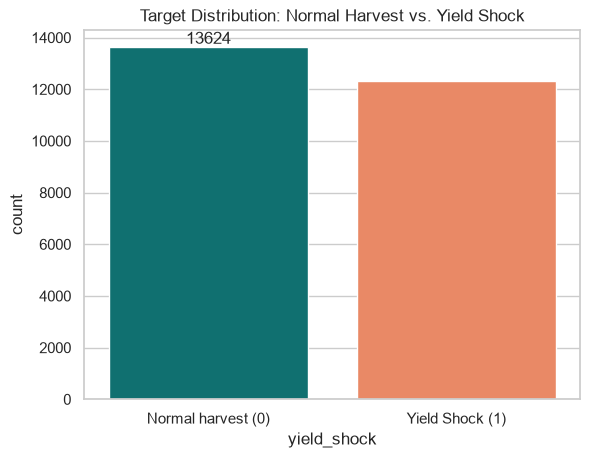

In [37]:
# df['yield_shock'].value_counts().plot(kind='bar', title="Yield Shock Distribution")

ax = sns.countplot(data=df, x="yield_shock", hue = 'yield_shock', palette = ['teal', 'coral'], legend=False)
ax.bar_label(ax.containers[0])
ax.set_xticklabels(['Normal harvest (0)', 'Yield Shock (1)'])
ax.set_title("Target Distribution: Normal Harvest vs. Yield Shock")

In [38]:
y = df['yield_shock']
x = df.drop(columns = ['value_hg_ha', 'yield_shock'])

print("X shape:", x.shape)
print("Y shape:", y.shape)


X shape: (25932, 6)
Y shape: (25932,)


## 2. Preprocessing & Feature Encoding Pipeline

In [39]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size = 0.2,
    stratify=y,
    random_state = 42
)

print(f"Training Set: {x_train.shape[0]} rows")
print(f"Testing Set: {x_test.shape[0]} rows")

Training Set: 20745 rows
Testing Set: 5187 rows


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = ['year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
categorical_cols = ['area', 'item']

yield_preprocessor = ColumnTransformer(
    transformers=[
        # (name, transformer, column_list)
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

x_train_transformed = yield_preprocessor.fit_transform(x_train)
print("Original shape: ", x_train.shape)
print("New shape: ", x_train_transformed.shape)

feature_names = yield_preprocessor.get_feature_names_out()
print("\nFirst 10 column names:")
print(feature_names[:10])


Original shape:  (20745, 6)
New shape:  (20745, 115)

First 10 column names:
['num__year' 'num__average_rain_fall_mm_per_year' 'num__pesticides_tonnes'
 'num__avg_temp' 'cat__area_Albania' 'cat__area_Algeria'
 'cat__area_Angola' 'cat__area_Argentina' 'cat__area_Armenia'
 'cat__area_Australia']


### 2.1 Baseline Feasibility Check: Arbitrary L1 Regularization (C=1.0)
A quick baseline test showing that default L1 penalty prunes 26 redundant features (leaving 89 active features).

In [41]:
from sklearn.linear_model import LogisticRegression
import numpy as np

yield_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, random_state=42, max_iter=1000)

yield_model.fit(x_train_transformed, y_train)

coefficients = yield_model.coef_[0]

mask = (coefficients != 0)
print(f"Total features: {len(coefficients)}")
print(f"Features kept: {np.sum(mask)}")
print(f"Features zeroed: {np.sum(~mask)}")

print("Kept features: ", feature_names[mask][:5])
print("UnKept features: ", feature_names[~mask][:5])

Total features: 115
Features kept: 89
Features zeroed: 26
Kept features:  ['num__year' 'num__average_rain_fall_mm_per_year' 'num__pesticides_tonnes'
 'num__avg_temp' 'cat__area_Albania']
UnKept features:  ['cat__area_Armenia' 'cat__area_Austria' 'cat__area_Belarus'
 'cat__area_Botswana' 'cat__area_Burkina Faso']


In [42]:
x_train_selected = x_train_transformed[:, mask]

x_test_processed = yield_preprocessor.transform(x_test)
x_test_selected = x_test_processed[:, mask]

print("Selected Train Shape: ", x_train_selected.shape)
print("Selected Test Shape: ", x_test_selected.shape)

final_yield_model = LogisticRegression(random_state=42, max_iter=1000)
final_yield_model.fit(x_train_selected, y_train)

Selected Train Shape:  (20745, 89)
Selected Test Shape:  (5187, 89)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

Accuracy:  0.7355 (73.55%)
Precision: 0.7185 (71.85%)
Recall:    0.7279 (72.79%)


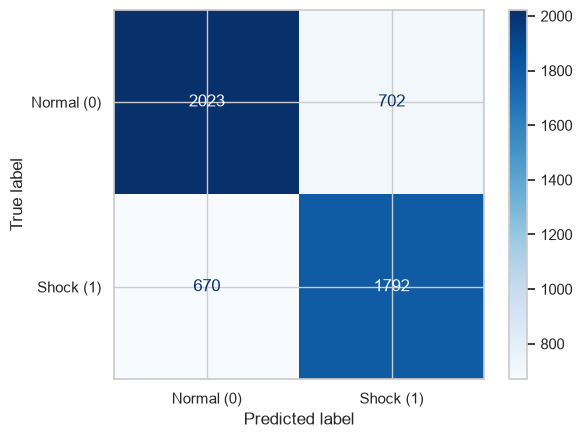

In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

y_prediction = final_yield_model.predict(x_test_selected)

acc = accuracy_score(y_test, y_prediction)
prec = precision_score(y_test, y_prediction)
rec = recall_score(y_test, y_prediction)

print(f"Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall:    {rec:.4f} ({rec*100:.2f}%)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_prediction,
    display_labels=['Normal (0)', 'Shock (1)'],
    cmap = 'Blues'
)

## 3. Multi-Model Benchmark on Full Feature Space (115 Features)
Evaluating baseline Logistic Regression, Decision Tree, and Random Forest using 5-fold cross-validation.

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state=42, n_jobs=-1)
}

benchmark_results = []

for name, model in models.items():
    cv_scores = cross_val_score(model, x_train_transformed, y_train, cv=5, scoring = "accuracy")
    
    model.fit(x_train_transformed, y_train)
    train_acc = model.score(x_train_transformed, y_train)
    
    benchmark_results.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "CV_Mean_Accuracy": round(cv_scores.mean(), 4),
        "CV_Standard_Deviation": round(cv_scores.std(), 4)
    })
    
benchmark_115_df = pd.DataFrame(benchmark_results)
print(benchmark_115_df)

                 Model  Train Accuracy  CV_Mean_Accuracy  \
0  Logistic Regression          0.7332            0.7286   
1        Decision Tree          1.0000            0.8411   
2        Random Forest          1.0000            0.8765   

   CV_Standard_Deviation  
0                 0.0069  
1                 0.0034  
2                 0.0054  


## 4. L1 Regularization Path & Feature Sparsity Analysis
Systematically sweeping the inverse regularization parameter $C \in [0.005, 10.0]$ to identify the optimal sparse feature subset.

In [45]:
C_values = [0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 10.0]
results = []

print("Running L1 Regularization Path across 7 penalty levels ...\n")

for c in C_values:
    l1_clf = LogisticRegression(
        l1_ratio = 1,
        solver="liblinear",
        C=c,
        max_iter=1000,
        random_state=42
    )
    
    cv_acc = cross_val_score(l1_clf, x_train_transformed, y_train, cv = 5, scoring="accuracy").mean()
    
    l1_clf.fit(x_train_transformed, y_train)

    n_active = int(np.sum(l1_clf.coef_[0] != 0))
    n_zeroed = x_train_transformed.shape[1] - n_active
    
    results.append({
        "C": c,
        "CV_Accuracy": round(cv_acc, 4),
        "Active_Features": n_active,
        "Zeroed_Features": n_zeroed
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
    
    

Running L1 Regularization Path across 7 penalty levels ...

     C  CV_Accuracy  Active_Features  Zeroed_Features
 0.005       0.7297                2              113
 0.010       0.7295                2              113
 0.050       0.7316                7              108
 0.100       0.7304               17               98
 0.500       0.7297               67               48
 1.000       0.7293               89               26
10.000       0.7287              109                6


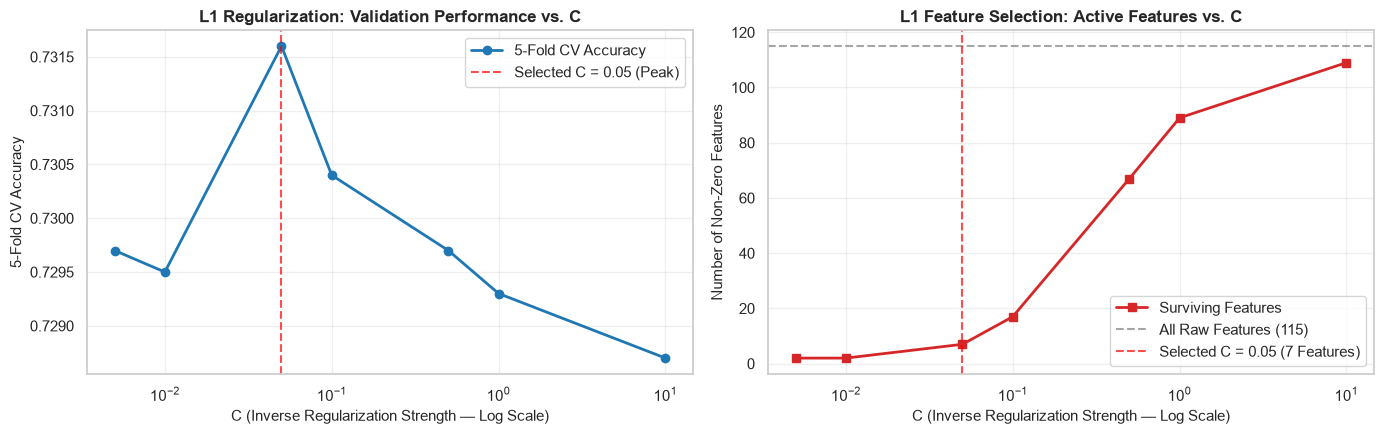

In [46]:
fig, axes = plt.subplots(1,2, figsize = (14,4.5))

# ----------------- PANEL 1: ACCURACY vs. C -----------------
axes[0].plot(results_df["C"], results_df["CV_Accuracy"], marker="o", color="#1f77b4", linewidth=2, label="5-Fold CV Accuracy")
axes[0].axvline(0.05, color="red", linestyle="--", alpha=0.7, label="Selected C = 0.05 (Peak)")
axes[0].set_xscale("log")  
axes[0].set_xlabel("C (Inverse Regularization Strength — Log Scale)", fontsize=11)
axes[0].set_ylabel("5-Fold CV Accuracy", fontsize=11)
axes[0].set_title("L1 Regularization: Validation Performance vs. C", fontsize=12, weight="bold")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# ----------------- PANEL 2: ACTIVE FEATURES vs. C -----------------
axes[1].plot(results_df["C"], results_df["Active_Features"], marker="s", color="#d62728", linewidth=2, label="Surviving Features")
axes[1].axhline(115, linestyle="--", color="gray", alpha=0.7, label="All Raw Features (115)")
axes[1].axvline(0.05, color="red", linestyle="--", alpha=0.7, label="Selected C = 0.05 (7 Features)")
axes[1].set_xscale("log")
axes[1].set_xlabel("C (Inverse Regularization Strength — Log Scale)", fontsize=11)
axes[1].set_ylabel("Number of Non-Zero Features", fontsize=11)
axes[1].set_title("L1 Feature Selection: Active Features vs. C", fontsize=12, weight="bold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Total Features Evaluated: 115
Features Retained (Non-Zero): 7
Features Discarded (Zeroed): 108

                           Feature  Coefficient  Abs_Importance
                         num__year    -1.091106        1.091106
                  cat__area_Brazil     0.793140        0.793140
            num__pesticides_tonnes    -0.336783        0.336783
                   cat__area_India     0.124428        0.124428
                 cat__item_Cassava    -0.027537        0.027537
                     num__avg_temp    -0.025273        0.025273
num__average_rain_fall_mm_per_year     0.012404        0.012404


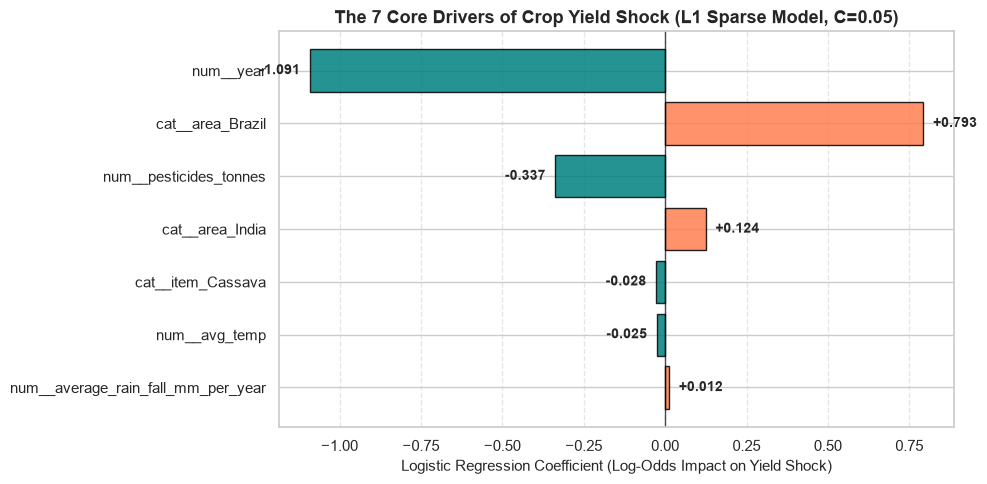

In [47]:
best_l1_clf = LogisticRegression(l1_ratio=1, solver='liblinear', C=0.05, random_state=42, max_iter=1000)

best_l1_clf.fit(x_train_transformed, y_train)

coefficients = best_l1_clf.coef_[0]

sparse_mask = (coefficients != 0)
surviving_features = feature_names[sparse_mask]
surviving_weights = coefficients[sparse_mask]

# 3. Create a ranked DataFrame
winners_df = pd.DataFrame({
    "Feature": surviving_features,
    "Coefficient": surviving_weights,
    "Abs_Importance": np.abs(surviving_weights)
}).sort_values(by="Abs_Importance", ascending=False).reset_index(drop=True)
print(f"Total Features Evaluated: {len(coefficients)}")
print(f"Features Retained (Non-Zero): {len(winners_df)}")
print(f"Features Discarded (Zeroed): {len(coefficients) - len(winners_df)}\n")
print(winners_df.to_string(index=False))

# 4. Plot Horizontal Bar Chart of the 7 Winners
fig, ax = plt.subplots(figsize=(10, 5))

# Color: Coral for positive (increases shock risk), Teal for negative (protective)
bar_colors = ["coral" if w > 0 else "teal" for w in winners_df["Coefficient"]]
y_positions = np.arange(len(winners_df))
ax.barh(y_positions, winners_df["Coefficient"], color=bar_colors, edgecolor="black", alpha=0.85)
ax.set_yticks(y_positions)
ax.set_yticklabels(winners_df["Feature"], fontsize=11)

ax.invert_yaxis()  # Put highest magnitude at the top
ax.axvline(0, color="black", linestyle="-", linewidth=1.0, alpha=0.7)
ax.set_xlabel("Logistic Regression Coefficient (Log-Odds Impact on Yield Shock)", fontsize=11)
ax.set_title("The 7 Core Drivers of Crop Yield Shock (L1 Sparse Model, C=0.05)", fontsize=13, weight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)

# Value annotations on each bar
for i, v in enumerate(winners_df["Coefficient"]):
    offset = 0.03 if v >= 0 else -0.03
    ha = "left" if v >= 0 else "right"
    ax.text(v + offset, i, f"{v:+.3f}", va="center", ha=ha, fontsize=10, weight="bold")
    
plt.tight_layout()
plt.show()

## 5. The Sparsity Impact Test: All 115 Features vs. 7 Winning Features
Testing model resilience when 94% of features are pruned.

In [48]:

x_train_sparse_selected = x_train_transformed[:, sparse_mask]


x_test_sparse_selected = x_test_processed[:, sparse_mask]

print("Selected Train Shape: ", x_train_sparse_selected.shape)
print("Selected Test Shape: ", x_test_sparse_selected.shape)





Selected Train Shape:  (20745, 7)
Selected Test Shape:  (5187, 7)


In [49]:
benchmark_results = []

for name, model in models.items():
    cv_scores = cross_val_score(model, x_train_sparse_selected, y_train, cv=5, scoring = "accuracy")
    
    model.fit(x_train_sparse_selected, y_train)
    train_acc = model.score(x_train_sparse_selected, y_train)
    
    benchmark_results.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "CV_Mean_Accuracy": round(cv_scores.mean(), 4),
        "CV_Standard_Deviation": round(cv_scores.std(), 4)
    })
    
benchmark_df = pd.DataFrame(benchmark_results)
print(benchmark_df)

                 Model  Train Accuracy  CV_Mean_Accuracy  \
0  Logistic Regression          0.7306            0.7306   
1        Decision Tree          0.8060            0.7021   
2        Random Forest          0.8060            0.7109   

   CV_Standard_Deviation  
0                 0.0050  
1                 0.0035  
2                 0.0047  


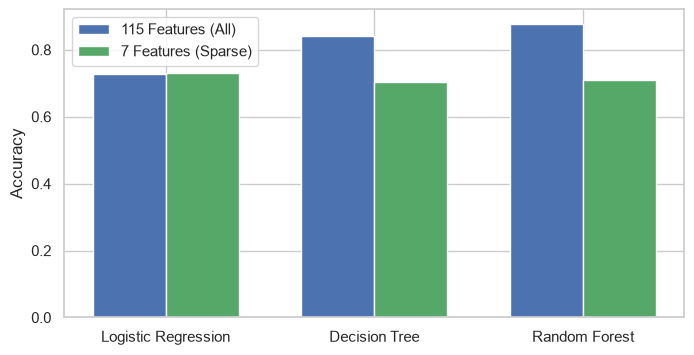

In [50]:
# Suppose we have 3 models
display_names = ['Logistic Regression', 'Decision Tree', 'Random Forest']
cv_115_Scores = benchmark_115_df["CV_Mean_Accuracy"].tolist()
cv_7_scores   = benchmark_df["CV_Mean_Accuracy"].tolist()


x = np.arange(len(display_names))


width = 0.35
fig, ax = plt.subplots(figsize=(8, 4))


bars1 = ax.bar(x - width/2, cv_115_Scores, width, label='115 Features (All)', color='#4c72b0')
bars2 = ax.bar(x + width/2, cv_7_scores,   width, label='7 Features (Sparse)', color='#55a868')


ax.set_xticks(x)
ax.set_xticklabels(display_names)
ax.set_ylabel("Accuracy")
ax.legend()
plt.show()

 ## 6. Champion Model Hyperparameter Optimization (GridSearchCV)
Tuning Random Forest tree depth and leaf constraints to mitigate overfitting while preserving maximum predictive power.

In [51]:
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_grid = {
    'max_depth': [20, 30, None],
    'min_samples_leaf': [1, 2],
    'n_estimators': [100]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

print("Running Grid Search across 6 parameter combinations (30 total fits)...")
grid_search.fit(x_train_transformed, y_train)

print("\n--- Grid Search Results ---")
print("Best 5-fold CV Accuracy:", round(grid_search.best_score_, 4))
print("Best Winning Parameters:", grid_search.best_params_)

Running Grid Search across 6 parameter combinations (30 total fits)...

--- Grid Search Results ---
Best 5-fold CV Accuracy: 0.8765
Best Winning Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


## 7. Final Holdout Evaluation & Model Serialization
Unlocking the unseen test set to evaluate the Champion Ensemble alongside the Ultra-Sparse Edge Model.

                   FINAL UNSEEN TEST SET BENCHMARK                   
                           Model Architecture  Feature Count Test Accuracy Test Precision Test Recall Test F1-Score
            Champion Ensemble (Random Forest)            115        88.70%         87.79%      88.51%        88.15%
Ultra-Sparse Edge Model (Logistic Regression)              7        73.49%         72.01%      72.22%        72.12%


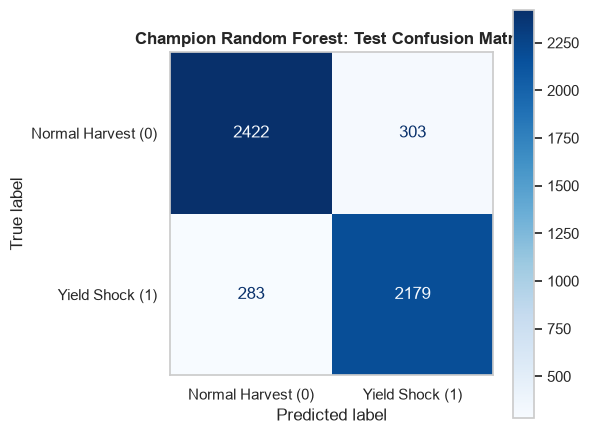


[OK] Successfully serialized Champion Random Forest to: models/champion_yield_model.joblib


In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

# Champion Random Forest (115 features)
champion_yield_model_rf = grid_search.best_estimator_
y_pred_rf = champion_yield_model_rf.predict(x_test_processed)

# Sparse logistic Regression(7 features)
sparse_lr = models["Logistic Regression"]
y_pred_lr = sparse_lr.predict(x_test_sparse_selected)

final_comparison = pd.DataFrame([
    {
        "Model Architecture": "Champion Ensemble (Random Forest)",
        "Feature Count": 115,
        "Test Accuracy": f"{accuracy_score(y_test, y_pred_rf)*100:.2f}%",
        "Test Precision": f"{precision_score(y_test, y_pred_rf)*100:.2f}%",
        "Test Recall": f"{recall_score(y_test, y_pred_rf)*100:.2f}%",
        "Test F1-Score": f"{f1_score(y_test, y_pred_rf)*100:.2f}%"
    },
    {
        "Model Architecture": "Ultra-Sparse Edge Model (Logistic Regression)",
        "Feature Count": 7,
        "Test Accuracy": f"{accuracy_score(y_test, y_pred_lr)*100:.2f}%",
        "Test Precision": f"{precision_score(y_test, y_pred_lr)*100:.2f}%",
        "Test Recall": f"{recall_score(y_test, y_pred_lr)*100:.2f}%",
        "Test F1-Score": f"{f1_score(y_test, y_pred_lr)*100:.2f}%"
    }
])
print("=" * 80)
print("                   FINAL UNSEEN TEST SET BENCHMARK                   ")
print("=" * 80)
print(final_comparison.to_string(index=False))
print("=" * 80)
# 4. Confusion Matrix for the Champion Model
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=["Normal Harvest (0)", "Yield Shock (1)"],
    cmap="Blues",
    ax=ax
)
ax.set_title("Champion Random Forest: Test Confusion Matrix", fontsize=12, weight="bold")
plt.grid(False)
plt.tight_layout()
plt.show()
# 5. Serialize Champion Model
joblib.dump(champion_yield_model_rf, "models/champion_yield_model.joblib")
print("\n[OK] Successfully serialized Champion Random Forest to: models/champion_yield_model.joblib")